<a href="https://colab.research.google.com/github/gayathridevies-arch/QSPR-LogS-Predictor-Machine-Learning-for-Molecular-Solubility/blob/main/projects_station.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Chem stands for Chemistry Module, not actual chemicals. Think of Chem as the "chemical engine" or "molecule reader" tool inside RDKit.

It is the tool that reads text (SMILES strings) and translates them into chemical structure objects that Python can work with.

You are importing the Descriptors calculator tool from inside RDKit's chemistry module (rdkit.Chem).

You are telling Python: "Go into the RDKit library, open the Chem folder, and bring out the Descriptors calculator so we can measure molecular properties.

In [ ]:
!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
aspirin_smiles="CC(=O)OC1=CC=CC=C1C(=O)O"
aspirin_molecule=Chem.MolFromSmiles(aspirin_smiles)
aspirin_mw=Descriptors.MolWt(aspirin_molecule)
print("Aspirin Molecular Weight:",aspirin_mw)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 50.4 MB/s eta 0:00:00
Aspirin Molecular Weight: 180.15899999999996


In [ ]:
data = {
    "Drug_Name": ["Aspirin", "Ibuprofen", "Caffeine", "Atorvastatin"],
    "SMILES": [
        "CC(=O)OC1=CC=CC=C1C(=O)O",  # Aspirin
        "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O",  # Ibuprofen
        "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",  # Caffeine
        "CC(C)C1=C(C(=C(N1CCC(CC(CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4",  # Atorvastatin
    ],
}
df=pd.DataFrame(data)
df["molecule"]=df["SMILES"].apply(Chem.MolFromSmiles) #In Pandas, .apply() is a shortcut that means: "Take a tool/function and run it on EVERY single row in this column, one by one.
df["molecular_weight"]=df["molecule"].apply(Descriptors.MolWt)
df["logp"]=df["molecule"].apply(Descriptors.MolLogP)
df["HBA"]=df["molecule"].apply(Descriptors.NumHAcceptors)
df["HBD"]=df["molecule"].apply(Descriptors.NumHDonors)
df[["Drug_Name","molecular_weight","logp","HBA","HBD"]]

,Drug_Name,molecular_weight,logp,HBA,HBD
0,Aspirin,180.159,1.3101,3,1
1,Ibuprofen,206.285,3.0732,1,1
2,Caffeine,194.194,-1.0293,3,0
3,Atorvastatin,558.650,6.3136,4,4


In [ ]:

!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
data = {
    "Drug_Name": ["Aspirin", "Ibuprofen", "Caffeine", "Atorvastatin"],
    "SMILES": [
        "CC(=O)OC1=CC=CC=C1C(=O)O",  # Aspirin
        "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O",  # Ibuprofen
        "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",  # Caffeine
        "CC(C)C1=C(C(=C(N1CCC(CC(CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4",  # Atorvastatin
    ],
}
df=pd.DataFrame(data)
df["molecule"]=df["SMILES"].apply(Chem.MolFromSmiles) #In Pandas, .apply() is a shortcut that means: "Take a tool/function and run it on EVERY single row in this column, one by one.
df["molecular_weight"]=df["molecule"].apply(Descriptors.MolWt)
df["logp"]=df["molecule"].apply(Descriptors.MolLogP)
df["HBA"]=df["molecule"].apply(Descriptors.NumHAcceptors)
df["HBD"]=df["molecule"].apply(Descriptors.NumHDonors)
def check_lipinski(row):
  violations=0
  if row["molecular_weight"]>500:
    violations+=1
  if row["logp"]>5:
    violations+=1
  if row["HBA"]>10:
    violations+=1
  if row["HBD"]>5:
    violations+=1
  return "Pass" if violations<=1 else "Fail"
df["Lipinski_status"]=df.apply(check_lipinski,axis=1)
df[["Drug_Name","molecular_weight","logp","HBA","HBD","Lipinski_status"]]


,Drug_Name,molecular_weight,logp,HBA,HBD,Lipinski_status
0,Aspirin,180.159,1.3101,3,1,Pass
1,Ibuprofen,206.285,3.0732,1,1,Pass
2,Caffeine,194.194,-1.0293,3,0,Pass
3,Atorvastatin,558.650,6.3136,4,4,Fail


Line Plots are for SequencesA line plot (kind="line") connects points with a continuous line. It is meant for data that changes over time or follows a sequence (like tracking stock prices over months, or temperature over 24 hours).Connecting Aspirin to Ibuprofen with a line doesn't make sense because they are completely separate molecules, not steps in a timeline!2. Bar Charts Hide RelationshipsA bar chart (kind="bar") is great for showing amounts or counts (like comparing the total sales of 4 different products).While you could make a bar chart showing the molecular weight of each drug, it only lets you look at one property at a time. It makes it hard to see how Molecular Weight and LogP interact together for a single drug.3. Scatter Plots Reveal "Rule Boundaries"A scatter plot (kind="scatter") places every drug as an individual point on a 2D coordinate grid.This makes it instantly visible where a molecule sits relative to Lipinski's cutoffs:X-axis (Horizontal): Molecular Weight $\le 500$Y-axis (Vertical): LogP $\le 5$By looking at a scatter plot, your eyes can immediately draw an invisible "safe zone" box in the bottom-left corner ($\text{MW} \le 500$ and $\text{LogP} \le 5$). Any drug dot landing inside that box passes both rules, and any dot landing outside (like Atorvastatin in the top right) clearly stands out as a violation!


Lipinski's rules measure Oral Bioavailability—meaning:

"If a human swallows this molecule in a pill, can it survive stomach acid and pass through the intestine wall into the bloodstream?"

<Axes: title={'center': 'Molecular Weight vs LogP'}, xlabel='molecular_weight', ylabel='logp'>

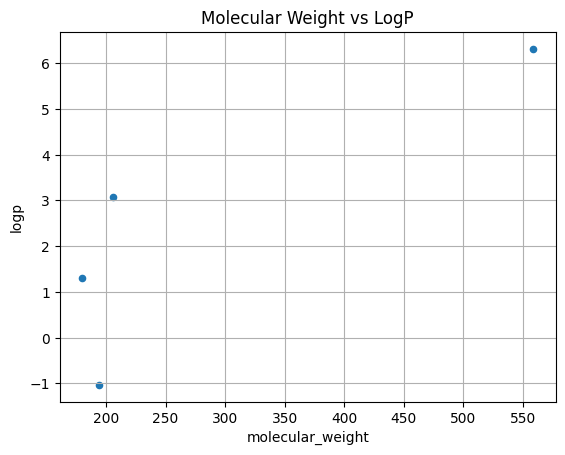

In [ ]:
data = {
    "Drug_Name": ["Aspirin", "Ibuprofen", "Caffeine", "Atorvastatin"],
    "SMILES": [
        "CC(=O)OC1=CC=CC=C1C(=O)O",  # Aspirin
        "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O",  # Ibuprofen
        "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",  # Caffeine
        "CC(C)C1=C(C(=C(N1CCC(CC(CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4",  # Atorvastatin
    ],
}
df=pd.DataFrame(data)
df["molecule"]=df["SMILES"].apply(Chem.MolFromSmiles) #In Pandas, .apply() is a shortcut that means: "Take a tool/function and run it on EVERY single row in this column, one by one.
df["molecular_weight"]=df["molecule"].apply(Descriptors.MolWt)
df["logp"]=df["molecule"].apply(Descriptors.MolLogP)
df["HBA"]=df["molecule"].apply(Descriptors.NumHAcceptors)
df["HBD"]=df["molecule"].apply(Descriptors.NumHDonors)
def check_lipinski(row):
  violations=0
  if row["molecular_weight"]>500:
    violations+=1
  if row["logp"]>5:
    violations+=1
  if row["HBA"]>10:
    violations+=1
  if row["HBD"]>5:
    violations+=1
  return "Pass" if violations<=1 else "Fail"
df["Lipinski_status"]=df.apply(check_lipinski,axis=1)
df[["Drug_Name","molecular_weight","logp","HBA","HBD","Lipinski_status"]]
df.plot(kind="scatter", x="molecular_weight",y="logp",title="Molecular Weight vs LogP",grid=True)

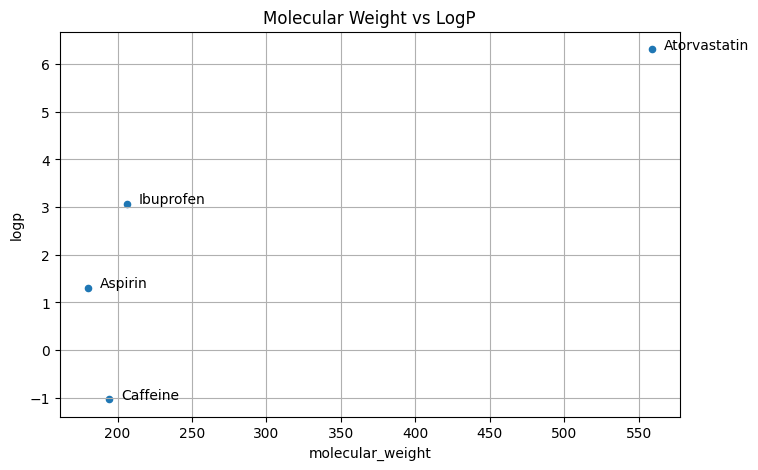

In [ ]:
data = {
    "Drug_Name": ["Aspirin", "Ibuprofen", "Caffeine", "Atorvastatin"],
    "SMILES": [
        "CC(=O)OC1=CC=CC=C1C(=O)O",  # Aspirin
        "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O",  # Ibuprofen
        "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",  # Caffeine
        "CC(C)C1=C(C(=C(N1CCC(CC(CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4",  # Atorvastatin
    ],
}
df=pd.DataFrame(data)
df["molecule"]=df["SMILES"].apply(Chem.MolFromSmiles) #In Pandas, .apply() is a shortcut that means: "Take a tool/function and run it on EVERY single row in this column, one by one.
df["molecular_weight"]=df["molecule"].apply(Descriptors.MolWt)
df["logp"]=df["molecule"].apply(Descriptors.MolLogP)
df["HBA"]=df["molecule"].apply(Descriptors.NumHAcceptors)
df["HBD"]=df["molecule"].apply(Descriptors.NumHDonors)
def check_lipinski(row):
  violations=0
  if row["molecular_weight"]>500:
    violations+=1
  if row["logp"]>5:
    violations+=1
  if row["HBA"]>10:
    violations+=1
  if row["HBD"]>5:
    violations+=1
  return "Pass" if violations<=1 else "Fail"
df["Lipinski_status"]=df.apply(check_lipinski,axis=1)
df[["Drug_Name","molecular_weight","logp","HBA","HBD","Lipinski_status"]]
ax=df.plot(kind="scatter", x="molecular_weight",y="logp",title="Molecular Weight vs LogP",grid=True,figsize=(8, 5))
for i in range(len(df)):
  ax.annotate(df["Drug_Name"][i],(df["molecular_weight"][i]+8,df["logp"][i]),fontsize=10)

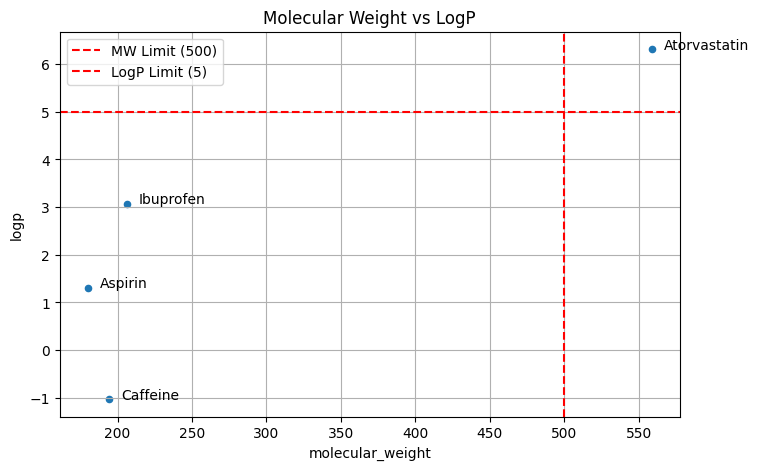

In [ ]:
data = {
    "Drug_Name": ["Aspirin", "Ibuprofen", "Caffeine", "Atorvastatin"],
    "SMILES": [
        "CC(=O)OC1=CC=CC=C1C(=O)O",  # Aspirin
        "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O",  # Ibuprofen
        "CN1C=NC2=C1C(=O)N(C(=O)N2C)C",  # Caffeine
        "CC(C)C1=C(C(=C(N1CCC(CC(CC(=O)O)O)O)C2=CC=C(C=C2)F)C3=CC=CC=C3)C(=O)NC4=CC=CC=C4",  # Atorvastatin
    ],
}
df=pd.DataFrame(data)
df["molecule"]=df["SMILES"].apply(Chem.MolFromSmiles) #In Pandas, .apply() is a shortcut that means: "Take a tool/function and run it on EVERY single row in this column, one by one.
df["molecular_weight"]=df["molecule"].apply(Descriptors.MolWt)
df["logp"]=df["molecule"].apply(Descriptors.MolLogP)
df["HBA"]=df["molecule"].apply(Descriptors.NumHAcceptors)
df["HBD"]=df["molecule"].apply(Descriptors.NumHDonors)
def check_lipinski(row):
  violations=0
  if row["molecular_weight"]>500:
    violations+=1
  if row["logp"]>5:
    violations+=1
  if row["HBA"]>10:
    violations+=1
  if row["HBD"]>5:
    violations+=1
  return "Pass" if violations<=1 else "Fail"
df["Lipinski_status"]=df.apply(check_lipinski,axis=1)
df[["Drug_Name","molecular_weight","logp","HBA","HBD","Lipinski_status"]]
ax=df.plot(kind="scatter", x="molecular_weight",y="logp",title="Molecular Weight vs LogP",grid=True,figsize=(8, 5))
ax.axvline(x=500, color="red", linestyle="--", label="MW Limit (500)")
ax.axhline(y=5, color="red", linestyle="--", label="LogP Limit (5)")
for i in range(len(df)):
  ax.annotate(df["Drug_Name"][i],(df["molecular_weight"][i]+8,df["logp"][i]),fontsize=10)
  ax.legend()

ax.axvline stands for ax (Canvas) + Vertical Line (v + line).ax.axvline(x=500): Draws a straight vertical line all the way up and down the graph, cutting through the horizontal X-axis at $X = 500$.ax.axhline(y=5): Draws a straight horizontal line (h + line) left to right across the graph, cutting through the vertical Y-axis at $Y = 5$.Together, these two lines cross to create a "danger wall." Any drug dot that goes to the right of $X = 500$ or above $Y = 5$ crosses the Lipinski rule limit!


When you give a line a label, and then call ax.legend() at the bottom of your code, Python automatically draws a neat little box in the corner saying:

🔴 -- MW Limit (500)

🔴 -- LogP Limit (5)

In Matplotlib, linestyle only recognizes specific predefined text codes to draw patterns on a graph:"--" (Two dashes): Draws a standard dashed line ($-- -$).":" (Colon): Draws a dotted line ($\cdot \cdot \cdot \cdot$)."-" (One dash): Draws a solid line (——)."-." (Dash-dot): Draws an alternating dash-dot line ($- \cdot - \cdot$).


saving high-resolution images (plt.savefig())

#🔬 Project: Small Molecule Chemical Space & Physicochemical Profiling

No parentheses (Attributes): Properties that describe the DataFrame's size or metadata (e.g., df.shape, df.columns, df.dtypes). You are just asking Pandas, "What are your properties?"

With parentheses () (Methods): Actions that perform an operation or calculation on the DataFrame (e.g., df.head(), df.describe(), df.mean()). You are telling Pandas, "Do this action for me!

                      Compound ID  measured log(solubility:mol/L)  \
0       1,1,1,2-Tetrachloroethane                           -2.18   
1           1,1,1-Trichloroethane                           -2.00   
2       1,1,2,2-Tetrachloroethane                           -1.74   
3           1,1,2-Trichloroethane                           -1.48   
4  1,1,2-Trichlorotrifluoroethane                           -3.04   

   ESOL predicted log(solubility:mol/L)               SMILES  
0                                -2.794       ClCC(Cl)(Cl)Cl  
1                                -2.232         CC(Cl)(Cl)Cl  
2                                -2.549       ClC(Cl)C(Cl)Cl  
3                                -1.961           ClCC(Cl)Cl  
4                                -3.077  FC(F)(Cl)C(F)(Cl)Cl  
(1144, 4)
Index(['Compound ID', 'measured log(solubility:mol/L)',
       'ESOL predicted log(solubility:mol/L)', 'SMILES'],
      dtype='object')
0    <rdkit.Chem.rdchem.Mol object at 0x7e984e22b140>
1    <r

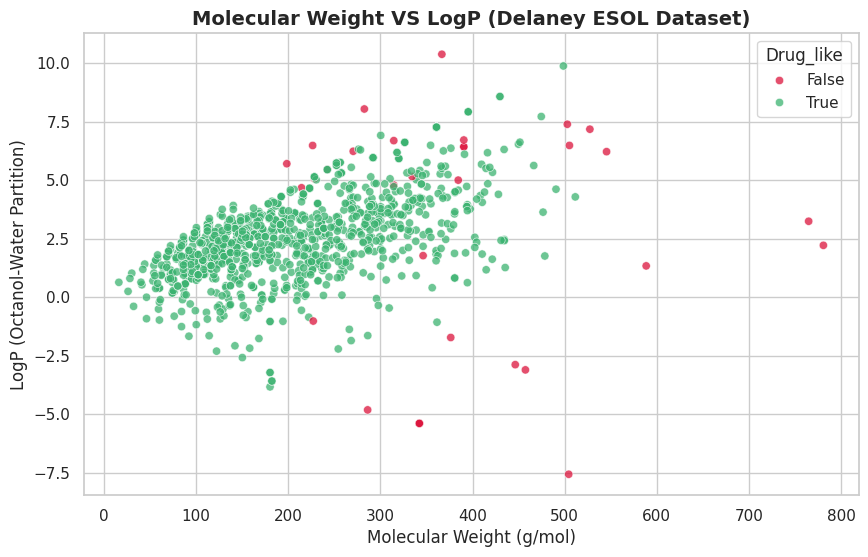

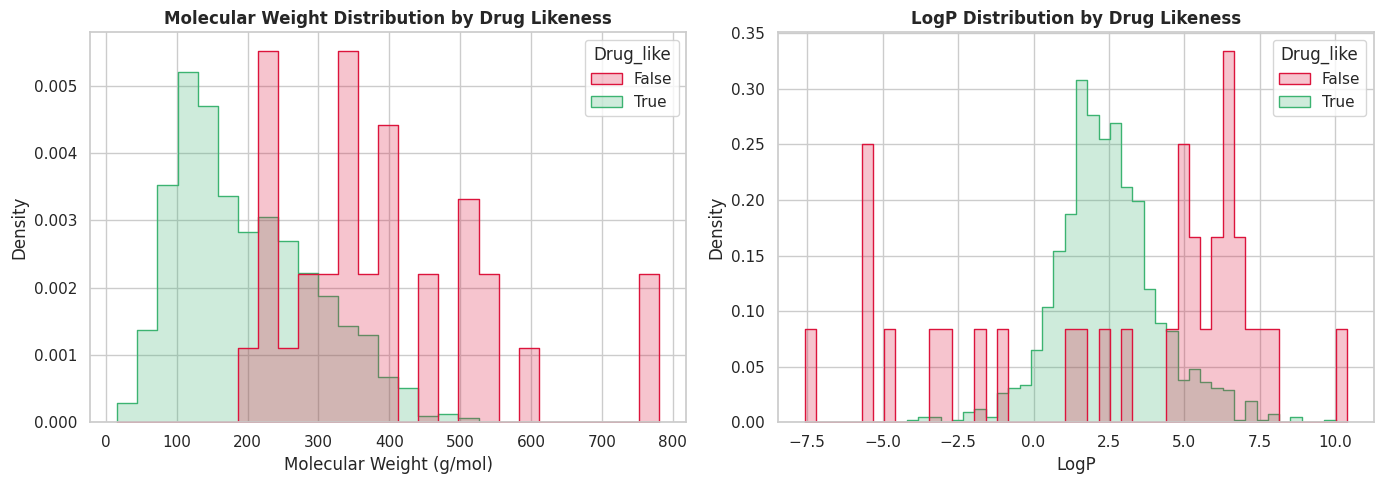

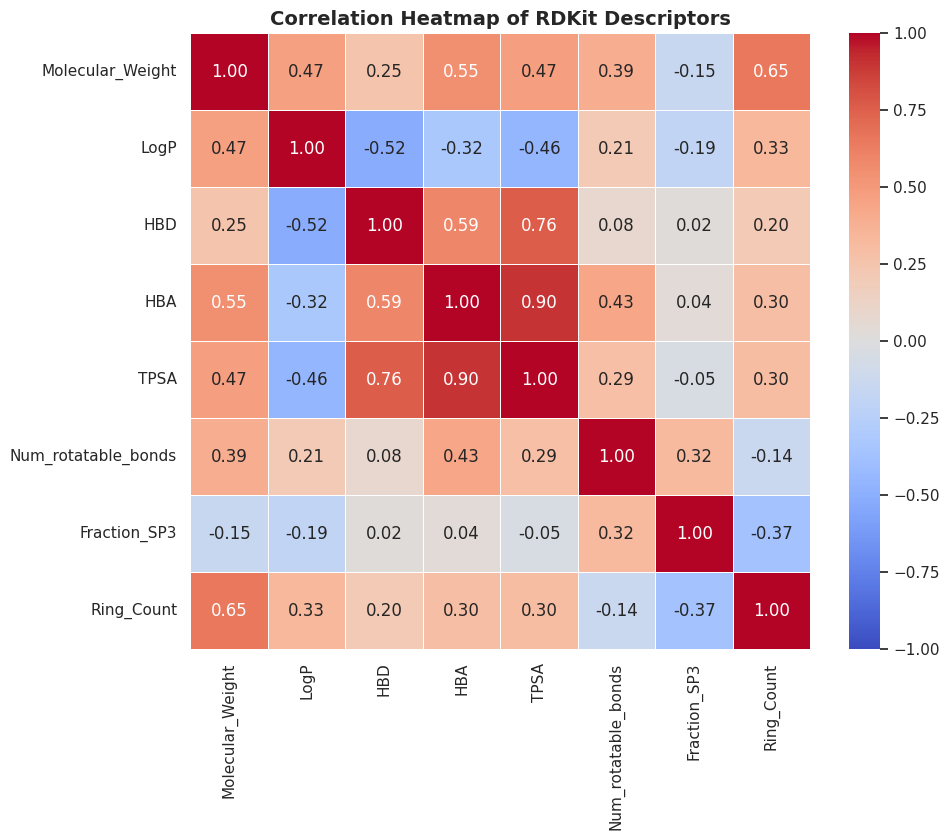

Sucess! Processed dataset saved as Delaney_processed_descriptors.csv


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
print(df.head())
print(df.shape)
print(df.columns)
df["Mol"]=df["SMILES"].apply(Chem.MolFromSmiles)
print(df["Mol"].head())
def calc_descriptors(molecule):
  return pd.Series({"Molecular_Weight":Descriptors.MolWt(molecule),"LogP":Descriptors.MolLogP(molecule),"HBD":Descriptors.NumHDonors(molecule),"HBA":Descriptors.NumHAcceptors(molecule),"TPSA":Descriptors.TPSA(molecule),"Num_rotatable_bonds":Descriptors.NumRotatableBonds(molecule),"Fraction_SP3":Descriptors.FractionCSP3(molecule),"Ring_Count":Descriptors.RingCount(molecule)})
descriptors_df=df["Mol"].apply(calc_descriptors)
df=pd.concat([df,descriptors_df],axis=1)
print(df.head())
print(df.dtypes)
lipinski_v1=df["Molecular_Weight"]>500
lipinski_v2=df["LogP"]>5
lipinski_v3=df["HBA"]>10
lipinski_v4=df["HBD"]>5
df["Lipinski_violations"]=(lipinski_v1.astype(int)+lipinski_v2.astype(int)+lipinski_v3.astype(int)+lipinski_v4.astype(int))
df["Veber_Pass"]=(df["Num_rotatable_bonds"]<=10)& (df["TPSA"]<=140)
df["Drug_like"] = (df["Lipinski_violations"]<=1)&(df["Veber_Pass"])
print(df["Drug_like"].value_counts())
df[df['Drug_like'] == False]
#scatter plot
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Molecular_Weight",y="LogP",hue="Drug_like",palette={True:"mediumseagreen",False:"Crimson"},alpha=0.75)#alpha -is for the dot transparency
plt.title("Molecular Weight VS LogP (Delaney ESOL Dataset)",fontsize=14,fontweight="bold")
plt.xlabel("Molecular Weight (g/mol)",fontsize=12)
plt.ylabel("LogP (Octanol-Water Partition)",fontsize=12)
plt.show()
#histogram plot
fig,axes=plt.subplots(1,2,figsize=(14,5)) #to create two graphs to compare it side by side
sns.histplot(data=df,x="Molecular_Weight",hue="Drug_like",element="step",stat="density",common_norm=False,palette={True:"mediumseagreen",False:"Crimson"},ax=axes[0])
axes[0].set_title("Molecular Weight Distribution by Drug Likeness",fontweight="bold")
axes[0].set_xlabel("Molecular Weight (g/mol)")
axes[0].set_ylabel("Density")
sns.histplot(data=df,x="LogP",hue="Drug_like",element="step",stat="density",common_norm=False,palette={True:"mediumseagreen",False:"Crimson"},ax=axes[1])
axes[1].set_title("LogP Distribution by Drug Likeness",fontweight="bold")
axes[1].set_xlabel("LogP")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()
numeric_cols=["Molecular_Weight","LogP","HBD","HBA","TPSA","Num_rotatable_bonds","Fraction_SP3","Ring_Count"] #HEATMAP
corr_matrix=df[numeric_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5,vmin=-1,vmax=1)
plt.title("Correlation Heatmap of RDKit Descriptors",fontweight="bold",fontsize=14)
plt.show()
output_filename="Delaney_processed_descriptors.csv"
df.to_csv(output_filename,index=False)
print(f"Sucess! Processed dataset saved as {output_filename}")
!pip install -q py3Dmol
import py3Dmol
from rdkit import Chem
from rdkit.Chem import AllChem
smiles_example="CC(=O)OC1=CC=CC=C1C(=O)O"
mol=Chem.MolFromSmiles(smiles_example)
mol=Chem.AddHs(mol)
AllChem.EmbedMolecule(mol,randomSeed=42)
AllChem.MMFFOptimizeMolecule(mol)
pdb_block=Chem.MolToPDBBlock(mol)
view=py3Dmol.view(width=400,height=300)
view.addModel(pdb_block,"pdb")
view.setStyle({"stick":{}})
view.zoomTo()
view.show()


If you ever needed 3D coordinates (for example, for molecular docking or quantum chemical modeling in TCCM), you would have to explicitly run 3D coordinate generation algorithms after MolFromSmiles:

mol = Chem.AddHs(mol) (Explicitly add hydrogens)

AllChem.EmbedMolecule(mol) (Generate 3D coordinates using distance geometry)

AllChem.MMFFOptimizeMolecule(mol) (Perform force-field energy minimization)

Additional Descriptors We Can AddTopological Polar Surface Area (TPSA) — Descriptors.TPSA(mol)What it measures: The surface area of polar atoms ($O$, $N$, and their attached $H$).Why it matters: Critical for predicting passive intestinal absorption and Blood-Brain Barrier (BBB) permeability.Number of Rotatable Bonds — Descriptors.NumRotatableBonds(mol)What it measures: Molecular flexibility.Why it matters: Part of Veber's Rules for oral bioavailability ($\le 10$ rotatable bonds).Fraction of $sp^3$ Carbons ($\text{Fraction } sp^3$) — Descriptors.FractionCSP3(mol)What it measures: The ratio of $sp^3$ hybridized carbons to total carbons (3D structural complexity vs. flat aromatic rings).Why it matters: Highly valued in modern drug discovery to assess "escape from flatland" and solubility.Ring Count — Descriptors.RingCount(mol)What it measures: Total number of rings in the chemical structure.

df.dtypes doesn't just give you a count—it lists every single column name side-by-side with its exact data type!

The Veber Rules (developed by Dr. Daniel Veber and his research team at GlaxoSmithKline in 2002) are an essential set of drug-likeness criteria that build upon Lipinski's classic Rule of Five.While Lipinski focused primarily on molecular weight and solubility parameters, Veber’s team discovered that molecular flexibility and surface area are even better predictors of whether a drug molecule can pass through the intestinal wall into the bloodstream (termed oral bioavailability).The 2 Criteria of Veber's RuleA molecule is considered to have high oral bioavailability under Veber's parameters if it satisfies both of the following conditions:1. Number of Rotatable Bonds $\le 10$ (Limits Molecular Flexibility)What it measures: A "rotatable bond" is any single non-ring bond attached to a non-hydrogen atom that can rotate freely ($360^\circ$).


Why it matters:If a molecule has too many rotatable bonds (very flexible, like a long piece of spaghetti), it loses a significant amount of conformational entropy when binding to a rigid protein target.Excessive flexibility also makes it harder for the molecule to adopt a compact shape that can easily cross cell membranes.Keeping rotatable bonds $\le 10$ keeps the molecule sufficiently rigid.


2. Topological Polar Surface Area (TPSA) $\le 140\text{ \AA}^2$ (Limits Polar Surface Area)What it measures: TPSA is the surface area (measured in square Ångströms, $\text{\AA}^2$) contributed by polar atoms—primarily Oxygen, Nitrogen, and their attached Hydrogen atoms.Why it matters:Polar surface area forms strong hydrogen bonds with water molecules in the surrounding gut fluid.If the polar surface area is too large ($> 140\text{ \AA}^2$), the water molecules cling too tightly to the drug, preventing it from shedding its water shell to pass through the hydrophobic lipid membrane of the intestinal cells.Keeping $\text{TPSA} \le 140\text{ \AA}^2$ ensures the molecule can easily strip off water molecules and diffuse across cellular membranes.

ule of Thumb in Pandas: Always enclose each comparison in parentheses (...) when combining conditions with & (AND) or | (OR).

Since df['Veber_Pass'] is already a standalone column of True/False values, Python doesn't get confused about order of operations.

However, if you want to put parentheses around it for consistency:
df['Drug_Like'] = (df['Lipinski_Violations'] <= 1) & (df['Veber_Pass'])  # ✅ Also completely valid!

What Seaborn Does Exceptionally Well (For Chemoinformatics)
Chemical Space Scatter Plots: Coloring 1,144 points by Drug_like status using just hue='Drug_like'.

Property Distribution Plots: Plotting overlapping density curves to compare molecular weight distributions across passing vs. failing molecules.

Categorical Boxplots / Violin Plots: Comparing LogP across different ring counts or violation categories without writing loops.

Correlation Heatmaps: Converting an entire correlation matrix of all 8 descriptors into a color-coded heatmap with a single line: sns.heatmap(df.corr()).

Other options for stat:

'count' (shows the actual number of molecules—this is the default).

'percent' (shows the percentage of the total).

'probability' (scales totals to sum to 1).

#heatmaps
In a data heatmap, instead of temperature, the colors represent correlation strength:

Deep Red = Strong positive correlation (as one property goes up, the other goes up strongly).

Deep Blue = Strong negative correlation (as one property goes up, the other goes down).

White/Light Gray = No correlation (zero relationship).


plt.figure(figsize=(10, 8))

# 1. MAKE SURE 'ax =' IS HERE!
ax = sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

# Your list with the capital L
Labels = [
    "Molecular Weight", "LogP", "H-Bond Donors",
    "H-Bond Acceptors", "TPSA", "Rotatable Bonds",
    "Fraction SP3", "Ring Count"
]

# This will now work because 'ax' and 'Labels' are both properly defined
ax.set_xticklabels(Labels, rotation=45, ha='right')
ax.set_yticklabels(Labels, rotation=0)
rotation to tilt the writings if they overlap and ha is horizontal alignment done after tilting

plt.tight_layout()
plt.show()

#Substructure Search & Functional Group Filtering

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,Molecule
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl,
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl,
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl,
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl,
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl,
...,...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC),
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C,
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O,
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O,

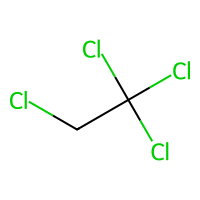
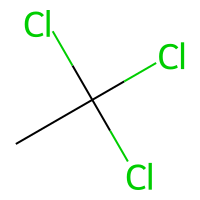
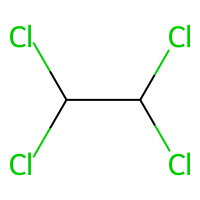
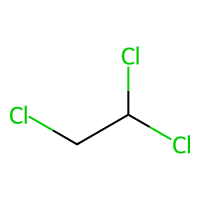
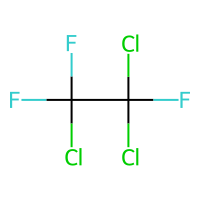
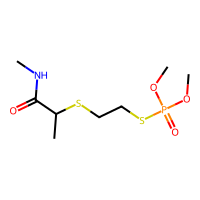
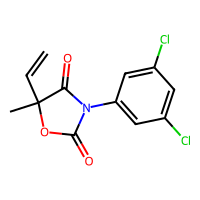
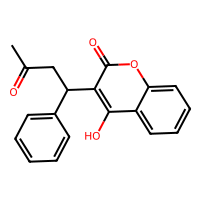
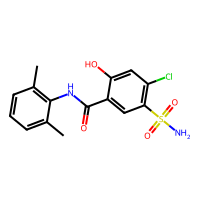
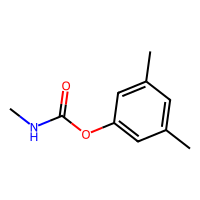

,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,Molecule,Has_Benzene
8,"1,2,3,4-Tetrachlorobenzene",-4.570,-4.546,Clc1ccc(Cl)c(Cl)c1Cl,,True
9,"1,2,3,4-Tetrahydronapthalene",-4.370,-3.447,C1CCc2ccccc2C1,,True
10,"1,2,3,5-Tetrachlorobenzene",-4.630,-4.621,Clc1cc(Cl)c(Cl)c(Cl)c1,,True
11,"1,2,3-Trichlorobenzene",-4.000,-4.008,Clc1cccc(Cl)c1Cl,,True
12,"1,2,3-Trimethylbenzene",-3.200,-3.312,Cc1cccc(C)c1C,,True
...,...,...,...,...,...,...
1133,Triphenylene,-6.726,-5.568,c1ccc2c(c1)c3ccccc3c4ccccc24,,True
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C,,True
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O,,True
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O,,True

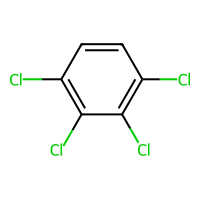
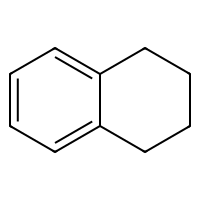
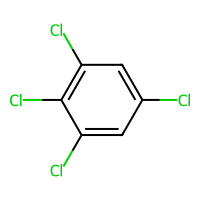
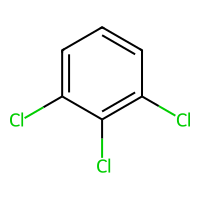
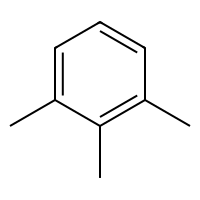
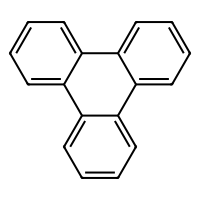
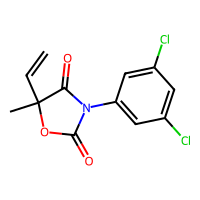
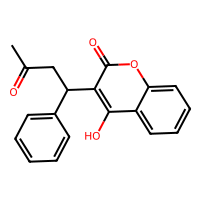
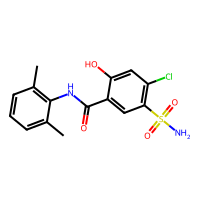
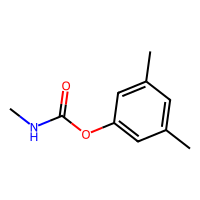

Total molecules: 1144
Molecules with Benzene: 578


In [ ]:
!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw,PandasTools
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
PandasTools.AddMoleculeColumnToFrame(df,smilesCol="SMILES", molCol="Molecule")
display(df)
PandasTools.RenderImagesInAllDataFrames(True)
query_smarts="c1ccccc1"
query_mol=Chem.MolFromSmarts(query_smarts)
df["Has_Benzene"]=df["Molecule"].apply(lambda x: x.HasSubstructMatch(query_mol) if x is not None else False)
matched_df=df[df["Has_Benzene"]==True]
display(matched_df)
print("Total molecules:",len(df))
print("Molecules with Benzene:", len(matched_df))


,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,Molecule
0,"1,1,1,2-Tetrachloroethane",-2.180,-2.794,ClCC(Cl)(Cl)Cl,
1,"1,1,1-Trichloroethane",-2.000,-2.232,CC(Cl)(Cl)Cl,
2,"1,1,2,2-Tetrachloroethane",-1.740,-2.549,ClC(Cl)C(Cl)Cl,
3,"1,1,2-Trichloroethane",-1.480,-1.961,ClCC(Cl)Cl,
4,"1,1,2-Trichlorotrifluoroethane",-3.040,-3.077,FC(F)(Cl)C(F)(Cl)Cl,
...,...,...,...,...,...
1139,vamidothion,1.144,-1.446,CNC(=O)C(C)SCCSP(=O)(OC)(OC),
1140,Vinclozolin,-4.925,-4.377,CC1(OC(=O)N(C1=O)c2cc(Cl)cc(Cl)c2)C=C,
1141,Warfarin,-3.893,-3.913,CC(=O)CC(c1ccccc1)c3c(O)c2ccccc2oc3=O,
1142,Xipamide,-3.790,-3.642,Cc1cccc(C)c1NC(=O)c2cc(c(Cl)cc2O)S(N)(=O)=O,

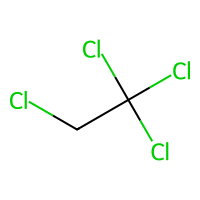
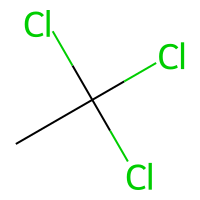
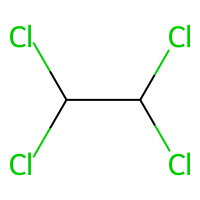
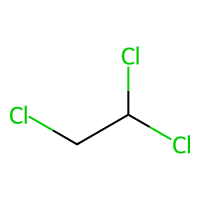
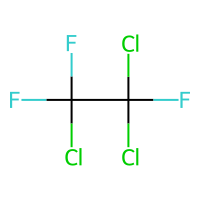
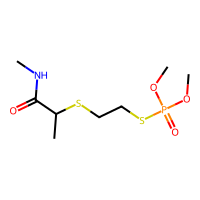
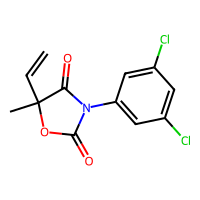
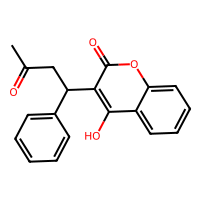
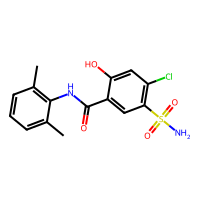
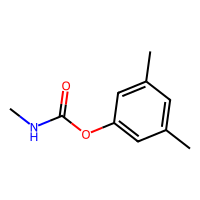

,Molecule,Has_Benzene,Has_Carbonyl,Has_Hydroxyl
0,,False,False,False
1,,False,False,False
2,,False,False,False
3,,False,False,False
4,,False,False,False

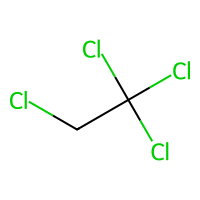
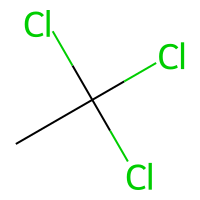
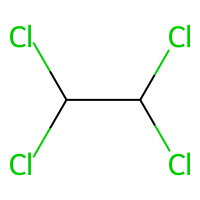
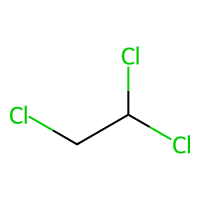
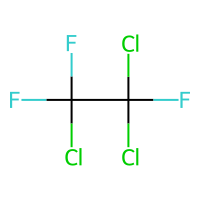

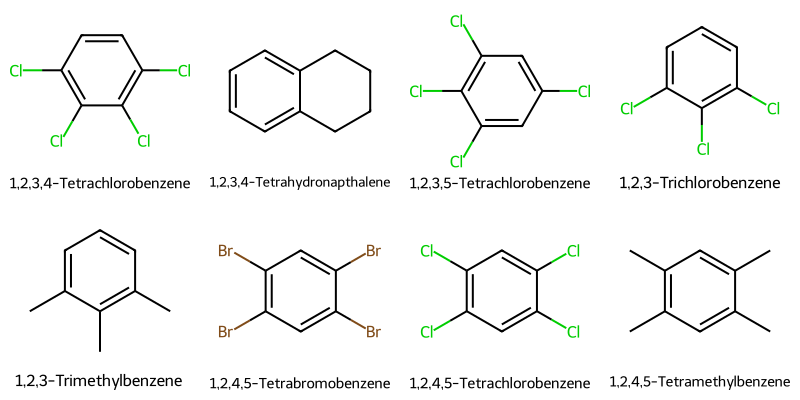

In [ ]:
!pip install rdkit
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw,PandasTools
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
PandasTools.AddMoleculeColumnToFrame(df,smilesCol="SMILES", molCol="Molecule")
display(df)
PandasTools.RenderImagesInAllDataFrames(True)
search_patterns={"Has_Benzene":"c1ccccc1","Has_Carbonyl":"C=O","Has_Hydroxyl":"[OH]"}
for col_name, query_smarts in search_patterns.items():
  query_mol=Chem.MolFromSmarts(query_smarts)
  df[col_name]=df["Molecule"].apply(lambda x:x.HasSubstructMatch(query_mol)if x is not None else False)
display(df[["Molecule","Has_Benzene","Has_Carbonyl","Has_Hydroxyl"]].head())
matched_df = df[df["Has_Benzene"]]
images=Draw.MolsToGridImage(matched_df["Molecule"].head(8).tolist(),molsPerRow=4,subImgSize=(200,200),legends=matched_df["Compound ID"].head(8).tolist())
images



AND: & (Both conditions must be true)

OR: | (At least one condition must be true)

NOT: ~ (Flips the condition, e.g., "does not have benzene")

# Option A: Show the Compound ID (what you used)
legends = matched_df["Compound ID"].head(8).tolist()

# Option B: Show the Solubility value instead
legends = matched_df["logS"].head(8).tolist()

# Option C: Show custom text labels you make up yourself
legends = [
    "Molecule A",
    "Molecule B",
    "Molecule C",
    "Molecule D",
    "Molecule E",
    "Molecule F",
    "Molecule G",
    "Molecule H",
]

matched_df['Molecule'].tolist(),  # Grabs ALL molecules, not just 8!
legends=matched_df['Compound ID'].tolist()  # Grabs ALL IDs for the labels!
)

Model R2 score: 0.698
Mean Absolute Error: 0.86


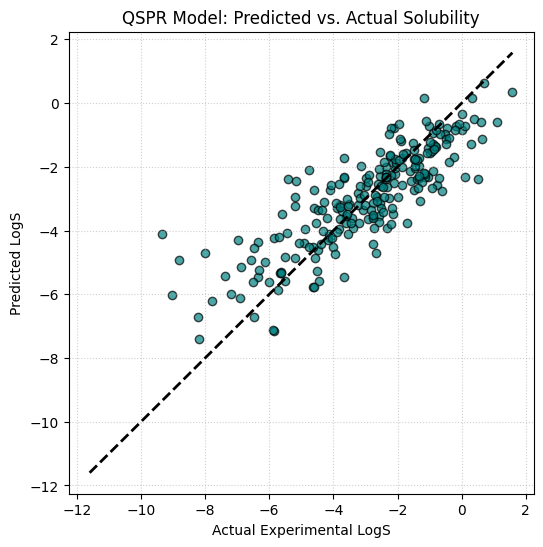

In [ ]:
!pip install rdkit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem,rdFingerprintGenerator
from rdkit import DataStructs
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split
df=pd.read_csv("https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv")
df.head(2)
df["Mol"]=df["SMILES"].apply(Chem.MolFromSmiles)
def get_fingerprint(mol):
  mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
  fp = mfpgen.GetFingerprint(mol)
  arr=np.zeros((1,))
  DataStructs.ConvertToNumpyArray(fp,arr)
  return arr
X=np.array([get_fingerprint(m)for m in df["Mol"]])
y=df["measured log(solubility:mol/L)"].values
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
model=RandomForestRegressor(n_estimators=100,random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
r2=r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
print("Model R2 score:",round(r2,3))
print("Mean Absolute Error:",round(mae,3))
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color="teal", alpha=0.7, edgecolors="k")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw=2)
plt.xlabel("Actual Experimental LogS")
plt.ylabel("Predicted LogS")
plt.title("QSPR Model: Predicted vs. Actual Solubility")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()




